# Movie Recommendation System

### Project Overview
This project aims to build a Content-Based Movie Recommendation System using the MovieLens dataset.

The system recommends movies based on their genres by identifying similarities between different movies.

### Objectives
- Load and explore the MovieLens dataset.
- Perform data cleaning and preprocessing.
- Extract movie genres as features.
- Calculate similarity between movies using Cosine Similarity.
- Recommend the top 5 similar movies based on user input.

### Technologies Used
- Python
- Pandas
- NumPy
- Scikit-learn
- Matplotlib
- Seaborn

### Recommendation Technique
Content-Based Filtering using CountVectorizer and Cosine Similarity.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.metrics.pairwise import cosine_similarity

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


## Dataset Loading

The MovieLens dataset contains information about movies, including their titles and genres, along with user ratings.

In this project, we will primarily use the `movies.csv` file because our recommendation system is based on movie genres.

We will also load `ratings.csv` to understand the dataset structure, although user ratings will not be used for calculating movie similarity.

In [2]:
# Load the MovieLens datasets

movies = pd.read_csv('/content/movies.csv')
ratings = pd.read_csv('/content/ratings.csv')

print("Movies Dataset:")
display(movies.head())

print("\nRatings Dataset:")
display(ratings.head())

Movies Dataset:


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy



Ratings Dataset:


,userId,movieId,rating,timestamp
0,1,1,4.0,964982703
1,1,3,4.0,964981247
2,1,6,4.0,964982224
3,1,47,5.0,964983815
4,1,50,5.0,964982931


## Dataset Overview

Before building the recommendation system, it is important to understand the structure and characteristics of the dataset.

We will examine the number of rows and columns, column names, data types and basic statistical information to understand the available data.

In [3]:
# Display dataset information

print("Movies Dataset Shape:", movies.shape)
print("Ratings Dataset Shape:", ratings.shape)

print("\nMovies Dataset Information:")
movies.info()

print("\nRatings Dataset Information:")
ratings.info()

Movies Dataset Shape: (9742, 3)
Ratings Dataset Shape: (100836, 4)

Movies Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9742 entries, 0 to 9741
Data columns (total 3 columns):
 #   Column   Non-Null Count  Dtype 
---  ------   --------------  ----- 
 0   movieId  9742 non-null   int64 
 1   title    9742 non-null   object
 2   genres   9742 non-null   object
dtypes: int64(1), object(2)
memory usage: 228.5+ KB

Ratings Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100836 entries, 0 to 100835
Data columns (total 4 columns):
 #   Column     Non-Null Count   Dtype  
---  ------     --------------   -----  
 0   userId     100836 non-null  int64  
 1   movieId    100836 non-null  int64  
 2   rating     100836 non-null  float64
 3   timestamp  100836 non-null  int64  
dtypes: float64(1), int64(3)
memory usage: 3.1 MB


In [4]:
# Generate statistical summary

print("Movies Dataset Summary:")
display(movies.describe(include='all'))

print("\nRatings Dataset Summary:")
display(ratings.describe())

Movies Dataset Summary:


,movieId,title,genres
count,9742.000000,9742,9742
unique,NaN,9737,951
top,NaN,Emma (1996),Drama
freq,NaN,2,1053
mean,42200.353623,NaN,NaN
std,52160.494854,NaN,NaN
min,1.000000,NaN,NaN
25%,3248.250000,NaN,NaN
50%,7300.000000,NaN,NaN
75%,76232.000000,NaN,NaN



Ratings Dataset Summary:


,userId,movieId,rating,timestamp
count,100836.000000,100836.000000,100836.000000,1.008360e+05
mean,326.127564,19435.295718,3.501557,1.205946e+09
std,182.618491,35530.987199,1.042529,2.162610e+08
min,1.000000,1.000000,0.500000,8.281246e+08
25%,177.000000,1199.000000,3.000000,1.019124e+09
50%,325.000000,2991.000000,3.500000,1.186087e+09
75%,477.000000,8122.000000,4.000000,1.435994e+09
max,610.000000,193609.000000,5.000000,1.537799e+09


## Data Quality Check

Data cleaning is an important step before building a recommendation system.

We will check for missing values and duplicate records in both datasets to ensure that the data is suitable for further processing.

In [5]:
# Check missing values

print("Missing Values in Movies Dataset:")
print(movies.isnull().sum())

print("\nMissing Values in Ratings Dataset:")
print(ratings.isnull().sum())

# Check duplicate records

print("\nDuplicate Movies:", movies.duplicated().sum())
print("Duplicate Ratings:", ratings.duplicated().sum())

Missing Values in Movies Dataset:
movieId    0
title      0
genres     0
dtype: int64

Missing Values in Ratings Dataset:
userId       0
movieId      0
rating       0
timestamp    0
dtype: int64

Duplicate Movies: 0
Duplicate Ratings: 0


## Data Cleaning and Preprocessing

In this step, we will clean and prepare the movies dataset before applying the recommendation algorithm.

The following operations will be performed:

- Check and handle missing values.
- Remove duplicate movie records.
- Remove unnecessary spaces from movie titles and genres.
- Prepare the genre information for feature extraction.

Since our recommendation system depends on movie genres, we will ensure that the genre information is properly formatted.

In [6]:
# Create a copy of the original dataset

movies_cleaned = movies.copy()

# Handle missing values
movies_cleaned.dropna(subset=['title', 'genres'], inplace=True)

# Remove duplicate records
movies_cleaned.drop_duplicates(subset='movieId', inplace=True)

# Clean movie titles and genres
movies_cleaned['title'] = movies_cleaned['title'].str.strip()
movies_cleaned['genres'] = movies_cleaned['genres'].str.strip()

# Reset index
movies_cleaned.reset_index(drop=True, inplace=True)

print("Data cleaning completed successfully!")

print("\nCleaned Dataset Shape:", movies_cleaned.shape)

display(movies_cleaned.head())

Data cleaning completed successfully!

Cleaned Dataset Shape: (9742, 3)


,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy


## Exploratory Data Analysis – Movie Genres

Exploratory Data Analysis (EDA) helps us understand the distribution of movie genres in the dataset.

Each movie may belong to multiple genres. We will separate the genre labels and count how frequently each genre appears.

This analysis will help us identify the most common movie categories.

In [7]:
# Separate genres and count their frequency

genre_counts = (
    movies_cleaned['genres']
    .str.split('|')
    .explode()
    .value_counts()
)

# Display genre frequency

print("Number of Movies in Each Genre:")
display(genre_counts)

Number of Movies in Each Genre:


,count
genres,
Drama,4361
Comedy,3756
Thriller,1894
Action,1828
Romance,1596
Adventure,1263
Crime,1199
Sci-Fi,980
Horror,978


## Visualization of Movie Genres

A bar chart is used to visualize the distribution of movie genres.

It helps identify the most frequently occurring genres and provides a better understanding of the MovieLens dataset.

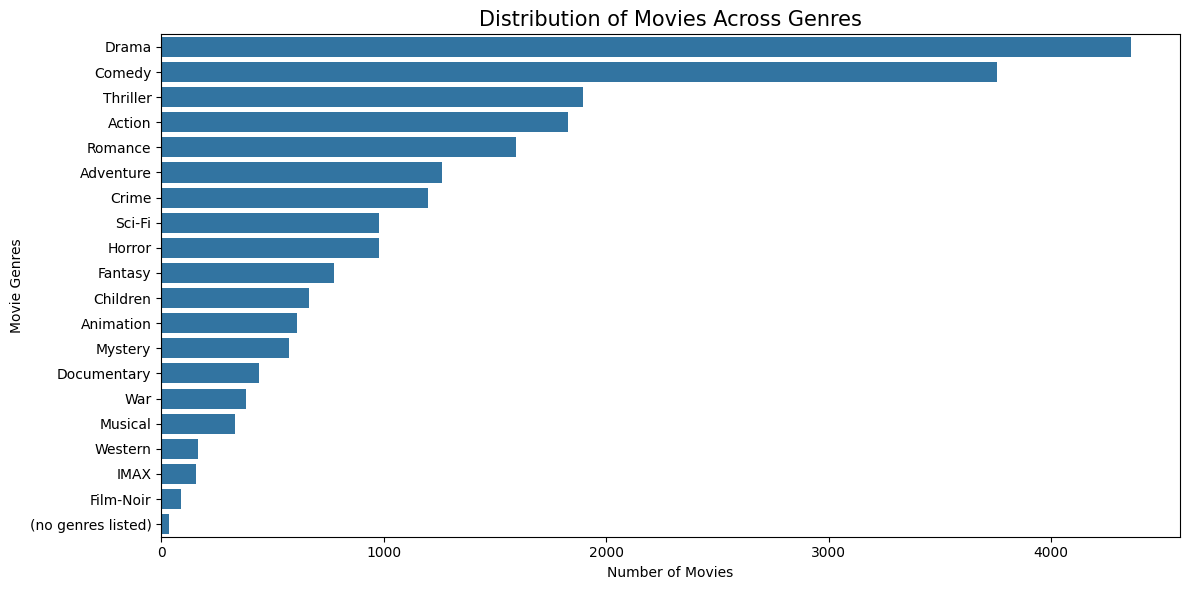

In [8]:
# Plot genre distribution

plt.figure(figsize=(12, 6))

sns.barplot(
    x=genre_counts.values,
    y=genre_counts.index
)

plt.title('Distribution of Movies Across Genres',
          fontsize=15)

plt.xlabel('Number of Movies')
plt.ylabel('Movie Genres')

plt.tight_layout()
plt.show()

In [9]:
# Display sample movie records after preprocessing

display(
    movies_cleaned[['movieId', 'title', 'genres']].head(10)
)

print("\nTotal Movies Available:", len(movies_cleaned))
print("Total Unique Movies:", movies_cleaned['movieId'].nunique())

,movieId,title,genres
0,1,Toy Story (1995),Adventure|Animation|Children|Comedy|Fantasy
1,2,Jumanji (1995),Adventure|Children|Fantasy
2,3,Grumpier Old Men (1995),Comedy|Romance
3,4,Waiting to Exhale (1995),Comedy|Drama|Romance
4,5,Father of the Bride Part II (1995),Comedy
5,6,Heat (1995),Action|Crime|Thriller
6,7,Sabrina (1995),Comedy|Romance
7,8,Tom and Huck (1995),Adventure|Children
8,9,Sudden Death (1995),Action
9,10,GoldenEye (1995),Action|Adventure|Thriller



Total Movies Available: 9742
Total Unique Movies: 9742


## Feature Extraction Using CountVectorizer

Feature extraction is the process of converting textual data into numerical values that can be understood by machine learning algorithms.

In this project, we use Scikit-learn's CountVectorizer to convert movie genres into numerical feature vectors.

Each genre is treated as a separate feature. The resulting matrix represents the presence or absence of different genres in each movie.

These feature vectors will be used to calculate similarity between movies.

In [10]:
# Initialize CountVectorizer

cv = CountVectorizer(
    tokenizer=lambda x: x.split('|'),
    token_pattern=None,
    lowercase=False
)

# Convert movie genres into numerical feature vectors

genre_matrix = cv.fit_transform(movies_cleaned['genres'])

print("Feature Extraction Completed Successfully!")

print("\nFeature Matrix Shape:", genre_matrix.shape)

print("\nExtracted Genres:")
print(cv.get_feature_names_out())

Feature Extraction Completed Successfully!

Feature Matrix Shape: (9742, 20)

Extracted Genres:
['(no genres listed)' 'Action' 'Adventure' 'Animation' 'Children' 'Comedy'
 'Crime' 'Documentary' 'Drama' 'Fantasy' 'Film-Noir' 'Horror' 'IMAX'
 'Musical' 'Mystery' 'Romance' 'Sci-Fi' 'Thriller' 'War' 'Western']


## Understanding the Genre Feature Matrix

The feature matrix contains numerical representations of movie genres.

Each row represents a movie, and each column represents a genre. A value of 1 indicates that the movie belongs to that genre, while 0 indicates that it does not.

This numerical representation allows us to measure similarity between different movies.

In [11]:
# Convert a small sample into a DataFrame for visualization

genre_features = pd.DataFrame(
    genre_matrix.toarray()[:10],
    columns=cv.get_feature_names_out()
)

display(genre_features)

,(no genres listed),Action,Adventure,Animation,Children,Comedy,Crime,Documentary,Drama,Fantasy,Film-Noir,Horror,IMAX,Musical,Mystery,Romance,Sci-Fi,Thriller,War,Western
0,0,0,1,1,1,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0
1,0,0,1,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
3,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,1,0,0,0,0
4,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0
5,0,1,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0
6,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0
7,0,0,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
8,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
9,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0


## Calculating Movie Similarity Using Cosine Similarity

Cosine Similarity is used to measure the similarity between two movies based on their genre feature vectors.

In this project, we use the cosine_similarity() function from Scikit-learn to calculate similarity scores between all movies.

A higher similarity score indicates that two movies share more similar genre characteristics.

The resulting similarity matrix will be used by our recommendation function to identify movies similar to a selected movie.

In [12]:
# Calculate cosine similarity between movies

cosine_sim = cosine_similarity(genre_matrix)

print("Cosine Similarity Calculated Successfully!")

print("\nSimilarity Matrix Shape:", cosine_sim.shape)

# Display similarity scores for first 5 movies

similarity_df = pd.DataFrame(
    cosine_sim[:5, :5],
    index=movies_cleaned['title'][:5],
    columns=movies_cleaned['title'][:5]
)

display(similarity_df)

Cosine Similarity Calculated Successfully!

Similarity Matrix Shape: (9742, 9742)


title,Toy Story (1995),Jumanji (1995),Grumpier Old Men (1995),Waiting to Exhale (1995),Father of the Bride Part II (1995)
title,,,,,
Toy Story (1995),1.000000,0.774597,0.316228,0.258199,0.447214
Jumanji (1995),0.774597,1.000000,0.000000,0.000000,0.000000
Grumpier Old Men (1995),0.316228,0.000000,1.000000,0.816497,0.707107
Waiting to Exhale (1995),0.258199,0.000000,0.816497,1.000000,0.577350
Father of the Bride Part II (1995),0.447214,0.000000,0.707107,0.577350,1.000000


## Building the Movie Recommendation System

In this step, we will create a recommendation function using the previously calculated Cosine Similarity matrix.

The function will accept a movie title as input, identify the selected movie, calculate its similarity with other movies, and recommend the top 5 most similar movies.

The recommendations will be generated based on movie genres using Content-Based Filtering.

In [13]:
# Create a function to recommend similar movies

def recommend_movies(movie_title, num_recommendations=5):

    # Check whether the movie exists in the dataset
    movie_matches = movies_cleaned[
        movies_cleaned['title'].str.lower() == movie_title.lower()
    ]

    if movie_matches.empty:
        print("Movie not found in the dataset!")
        print("Please enter a valid movie title.")
        return

    # Get the index of the selected movie
    movie_index = movie_matches.index[0]

    # Get similarity scores for the selected movie
    similarity_scores = list(enumerate(cosine_sim[movie_index]))

    # Sort movies by similarity score in descending order
    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    # Exclude the selected movie itself
    similarity_scores = [
        score for score in similarity_scores
        if score[0] != movie_index
    ]

    # Select top similar movies
    top_movies = similarity_scores[:num_recommendations]

    # Display recommendations
    print(f"\nMovies similar to '{movies_cleaned.iloc[movie_index]['title']}':\n")

    for rank, (index, score) in enumerate(top_movies, start=1):
        recommended_title = movies_cleaned.iloc[index]['title']

        print(f"{rank}. {recommended_title} (Similarity Score: {score:.2f})")

## Testing the Movie Recommendation System

After building the recommendation function, we will test it using different movie titles.

The system will recommend five movies that have the most similar genre characteristics to the selected movie.

This testing helps verify whether the recommendation system is working correctly.

In [14]:
# Test the recommendation system

recommend_movies('Toy Story (1995)')


Movies similar to 'Toy Story (1995)':

1. Antz (1998) (Similarity Score: 1.00)
2. Toy Story 2 (1999) (Similarity Score: 1.00)
3. Adventures of Rocky and Bullwinkle, The (2000) (Similarity Score: 1.00)
4. Emperor's New Groove, The (2000) (Similarity Score: 1.00)
5. Monsters, Inc. (2001) (Similarity Score: 1.00)


In [15]:
recommend_movies('Jumanji (1995)')


Movies similar to 'Jumanji (1995)':

1. Indian in the Cupboard, The (1995) (Similarity Score: 1.00)
2. NeverEnding Story III, The (1994) (Similarity Score: 1.00)
3. Escape to Witch Mountain (1975) (Similarity Score: 1.00)
4. Darby O'Gill and the Little People (1959) (Similarity Score: 1.00)
5. Return to Oz (1985) (Similarity Score: 1.00)


In [16]:
recommend_movies('Jurassic Park (1993)')


Movies similar to 'Jurassic Park (1993)':

1. Independence Day (a.k.a. ID4) (1996) (Similarity Score: 1.00)
2. Escape from L.A. (1996) (Similarity Score: 1.00)
3. Abyss, The (1989) (Similarity Score: 1.00)
4. Escape from New York (1981) (Similarity Score: 1.00)
5. Star Trek: First Contact (1996) (Similarity Score: 1.00)


In [17]:
# Test with an invalid movie title

recommend_movies('Unknown Movie')

Movie not found in the dataset!
Please enter a valid movie title.


## Visualization of Movie Similarity

A heatmap is used to visualize the Cosine Similarity scores between movies.

It helps us understand how closely different movies are related based on their genres.

Higher similarity values indicate stronger genre similarity between movies.

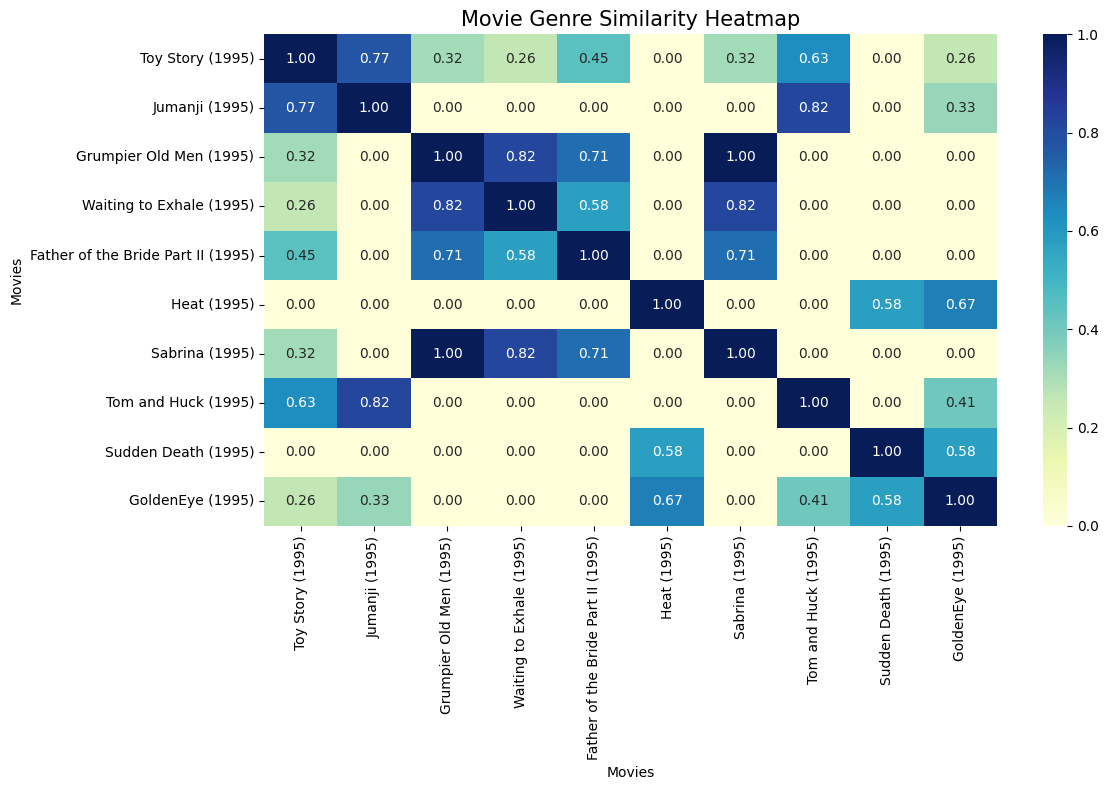

In [18]:
# Select the first 10 movies for visualization

sample_similarity = cosine_sim[:10, :10]

sample_titles = movies_cleaned['title'].iloc[:10]

# Create similarity heatmap

plt.figure(figsize=(12, 8))

sns.heatmap(
    sample_similarity,
    xticklabels=sample_titles,
    yticklabels=sample_titles,
    annot=True,
    cmap='YlGnBu',
    fmt='.2f'
)

plt.title('Movie Genre Similarity Heatmap', fontsize=15)
plt.xlabel('Movies')
plt.ylabel('Movies')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

## Displaying Recommendations in Tabular Format

In this section, we will present movie recommendations in a structured table containing movie titles and their corresponding similarity scores.

This provides a clear comparison of recommended movies and helps users understand the recommendation results.

In [19]:
# Create a function to display recommendations in table format

def get_recommendations(movie_title, num_recommendations=5):

    movie_matches = movies_cleaned[
        movies_cleaned['title'].str.lower() == movie_title.lower()
    ]

    if movie_matches.empty:
        print("Movie not found in the dataset!")
        return

    movie_index = movie_matches.index[0]

    similarity_scores = list(enumerate(cosine_sim[movie_index]))

    similarity_scores = sorted(
        similarity_scores,
        key=lambda x: x[1],
        reverse=True
    )

    similarity_scores = [
        item for item in similarity_scores
        if item[0] != movie_index
    ]

    top_movies = similarity_scores[:num_recommendations]

    recommendations = pd.DataFrame([
        {
            'Rank': rank,
            'Movie Title': movies_cleaned.iloc[index]['title'],
            'Genres': movies_cleaned.iloc[index]['genres'],
            'Similarity Score': round(score, 3)
        }
        for rank, (index, score) in enumerate(top_movies, start=1)
    ])

    return recommendations


# Display recommendations in table format

display(get_recommendations('Toy Story (1995)'))

,Rank,Movie Title,Genres,Similarity Score
0,1,Antz (1998),Adventure|Animation|Children|Comedy|Fantasy,1.0
1,2,Toy Story 2 (1999),Adventure|Animation|Children|Comedy|Fantasy,1.0
2,3,"Adventures of Rocky and Bullwinkle, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
3,4,"Emperor's New Groove, The (2000)",Adventure|Animation|Children|Comedy|Fantasy,1.0
4,5,"Monsters, Inc. (2001)",Adventure|Animation|Children|Comedy|Fantasy,1.0


## Conclusion

In this project, a Content-Based Movie Recommendation System was successfully developed using the MovieLens dataset.

The system uses Pandas for data processing, CountVectorizer for feature extraction, and Cosine Similarity from Scikit-learn to calculate similarities between movies based on their genres.

It can recommend the top 5 similar movies for a selected movie title.

Through this project, we learned the fundamentals of recommendation systems, data preprocessing, feature extraction, similarity measurement and data visualization.

The project demonstrates how machine learning techniques can be applied to build a simple movie recommendation system.